In [4]:
import matplotlib.pyplot as plt
import numpy as np

In [223]:
def generate_data(num_samples, scale, centers, seed=42):
    np.random.seed(seed)
    centers = np.array(centers)
    num_centers, dimensions = centers.shape
    
    x = []
    y = []
    for i, center in enumerate(centers):
        points = np.random.normal(loc=center, scale=scale, size=(num_samples // num_centers, dimensions))
        labels = np.full(num_samples // num_centers, i)
        x.extend(points)
        y.extend(labels)
    x, y = np.array(x), np.array(y)
    indices = np.arange(num_samples)
    np.random.shuffle(indices)
    x = x[indices]
    y = y[indices].astype(int)
    return x, y

distance = 4
samples = 4
x, y = generate_data(600, 1, 
                    [[distance * np.cos(1 / samples * np.pi), distance * np.sin(1 / samples * np.pi)], 
                     [distance * np.cos(3 / samples * np.pi), distance * np.sin(3 / samples * np.pi)], 
                     [distance * np.cos(5 / samples * np.pi), distance * np.sin(5 / samples * np.pi)], 
                     [distance * np.cos(7 / samples * np.pi), distance * np.sin(7 / samples * np.pi)]], 
                    seed=42)

In [224]:
def plot_tvp(x, y, m):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), facecolor='grey')
    ax1.grid(linestyle='--', alpha=0.4)
    ax2.grid(linestyle='--', alpha=0.4)
    
    scat1 = ax1.scatter(x=x[:, 0], y=x[:, 1], c=y)
    ax1.set_title('points')
    plt.colorbar(scat1, ax=ax1)
    
    scat2 = ax2.scatter(x=x[:, 0], y=x[:, 1], c=m.predict(x))
    ax2.scatter(m.centroids[:, 0], m.centroids[:, 1], c='k', marker="*", s=100)
    ax2.set_title('clusters')
    plt.colorbar(scat2, ax=ax2)

In [256]:
class KMeans:
    def __init__(self, k):
        self.k = k
        self.centroids = None
    
    def fit(self, x, max_iters=100):
        x = np.array(x)
        self.centroids = np.random.uniform(np.min(x, axis=0), np.max(x, axis=0), size=(self.k, x.shape[1]))

        for _ in range(max_iters):
            dist_sq = np.sum((x[:, np.newaxis, :] - self.centroids)**2, axis=2)
            closest = np.argmin(dist_sq, axis=1)
            cluster_centers = []
            for i in range(self.k):
                points_in_cluster = x[closest == i]
                if len(points_in_cluster) > 0:
                    cluster_centers.append(np.mean(points_in_cluster, axis=0))
                else:
                    cluster_centers.append(self.centroids[i])

            if np.max(np.abs(np.array(cluster_centers) - self.centroids)) < 0.000000001:
                break
            else:
                self.centroids = np.array(cluster_centers)

    def predict(self, x):
        x = np.array(x)
        dist_sq = np.sum((x[:, np.newaxis, :] - self.centroids)**2, axis=2)
        return np.argmin(dist_sq, axis=1)

    def score(self, x):
        x = np.array(x)
        dist_sq = np.sum((x[:, np.newaxis, :] - self.centroids)**2, axis=2)
        return -np.sum(np.min(dist_sq, axis=1))

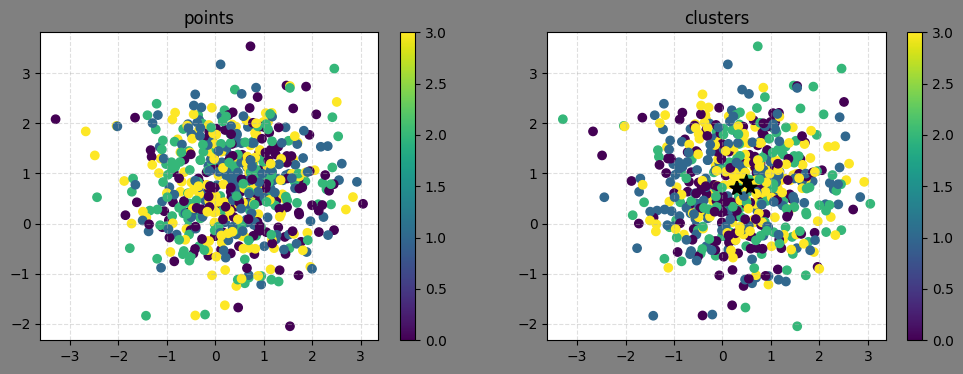

In [250]:
kmeans = KMeans(k=4)
kmeans.fit(x, max_iters=100)
plot_tvp(x, y, kmeans)

In [251]:
kmeans.score(x)

-59714.107984287504

In [228]:
dist = 3
x, y = generate_data(600, 1, 
                    [[ dist,  dist,  dist], 
                     [-dist, -dist,  dist], 
                     [-dist,  dist, -dist], 
                     [ dist, -dist, -dist]], 
                    seed=42)

(-7.0, 7.0)

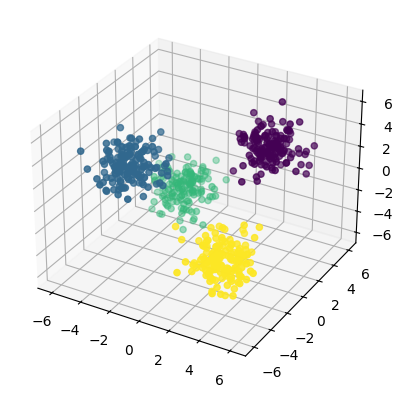

In [229]:
def plot_tvp_3d(x, y, m):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), facecolor='grey', subplot_kw={'projection': '3d'})
    ax1.grid(linestyle='--', alpha=0.4)
    ax2.grid(linestyle='--', alpha=0.4)
    
    scat1 = ax1.scatter(x[:, 0], x[:, 1], x[:, 2], c=y)
    ax1.set_title('points')
    plt.colorbar(scat1, ax=ax1)
    
    scat2 = ax2.scatter(x[:, 0], x[:, 1], x[:, 2], c=m.predict(x), alpha=0.1)
    ax2.scatter(m.centroids[:, 0], m.centroids[:, 1], m.centroids[:, 2], c='k', marker="*", s=100, zorder=1000, alpha=1.0)
    ax2.set_title('clusters')
    plt.colorbar(scat2, ax=ax2)
    for ax in [ax1, ax2]:
        ax.set_xlim(-7, 7)
        ax.set_ylim(-7, 7)
        ax.set_zlim(-7, 7)
    
ax = plt.subplot(projection='3d')
ax.scatter(x[:, 0], x[:, 1], x[:, 2], c=y)
ax.set_xlim(-7, 7)
ax.set_ylim(-7, 7)
ax.set_zlim(-7, 7)

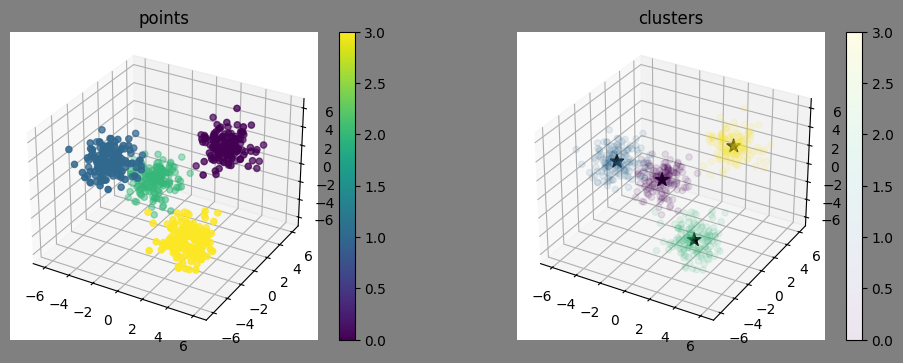

In [231]:
kmeans = KMeans(k=4)
kmeans.fit(x, max_iters=1000)
plot_tvp_3d(x, y, kmeans)

In [232]:
kmeans.score(x)

-1747.8677473516032

In [257]:
x, y = generate_data(600, 1, 
                    [np.random.uniform(0, 1, size=(100,)), 
                     np.random.uniform(0, 1, size=(100,)), 
                     np.random.uniform(0, 1, size=(100,)), 
                     np.random.uniform(0, 1, size=(100,))], 
                    seed=42)
np.array(x).shape

(600, 100)

In [262]:
kmeans = KMeans(k=20)
kmeans.fit(x, max_iters=1000)
kmeans.score(x)

-57484.145073675085